In [ ]:
import mysql.connector
from getpass import getpass

password = getpass("Enter your MySQL password: ")

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password=NewPassword@123,
    database="customer_churn_db"
)

print("Connected to MySQL successfully!")

In [1]:
import mysql.connector
from getpass import getpass

password = getpass("MySQL password:NewPassword@123") 

try:
    conn = mysql.connector.connect(
        host="127.0.0.1",
        port=3306,
        user="root",
        password=password,
        database="customer_churn_db",
        connection_timeout=5
    )
    print("Connected successfully!")
except mysql.connector.Error as e:
    print("Connection failed:", e)

Connection failed: 1045 (28000): Access denied for user 'root'@'localhost' (using password: NO)


In [25]:
%pip install mysql-connector-python

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from getpass import getpass
import mysql.connector

password = getpass("Enter your MySQL password: "NewPassword@123)

print("Password entered:", bool(password))

Password entered: False


In [7]:
from getpass import getpass
import mysql.connector

password = getpass("Enter your MySQL password: ")

try:
    conn = mysql.connector.connect(
        host="127.0.0.1",
        port=3306,
        user="root",
        password=password,
        database="customer_churn_db",
        connection_timeout=5
    )
    print("Connected successfully!")

except mysql.connector.Error as e:
    print("Connection failed:", e)

Connection failed: 1045 (28000): Access denied for user 'root'@'localhost' (using password: NO)


In [8]:
import mysql.connector

try:
    conn = mysql.connector.connect(
        host="127.0.0.1",
        port=3306,
        user="root",
        password="NewPassword@123",
        database="customer_churn_db",
        connection_timeout=5
    )

    print("Connected successfully!")

except mysql.connector.Error as e:
    print("Connection failed:", e)

Connected successfully!


In [10]:
import pandas as pd

original_df = pd.read_csv(
    "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("CSV rows:", len(original_df))
print("CSV columns:", len(original_df.columns))
print("Unique customers:", original_df["customerID"].nunique())

CSV rows: 7043
CSV columns: 21
Unique customers: 7043


In [12]:
import pandas as pd
import mysql.connector

# Load the CSV
df_import = pd.read_csv(
    "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

# Convert blank values to None for MySQL
df_import["TotalCharges"] = df_import["TotalCharges"].replace(
    r"^\s*$", None, regex=True
)

data = df_import.astype(object).where(
    pd.notna(df_import), None
)

columns = df_import.columns.tolist()
column_sql = ", ".join(f"`{col}`" for col in columns)
placeholders = ", ".join(["%s"] * len(columns))

insert_sql = f"""
INSERT INTO customer_churn ({column_sql})
VALUES ({placeholders})
"""

cursor = conn.cursor()

try:
    cursor.execute("DELETE FROM customer_churn")

    cursor.executemany(
        insert_sql,
        list(data.itertuples(index=False, name=None))
    )

    conn.commit()
    print("Rows inserted:", cursor.rowcount)

except Exception as e:
    conn.rollback()
    print("Import failed:", e)

finally:
    cursor.close()

Rows inserted: 7043


In [11]:
print(
    original_df.loc[
        original_df["tenure"] == 0,
        ["customerID", "tenure", "TotalCharges"]
    ]
)

      customerID  tenure TotalCharges
488   4472-LVYGI       0             
753   3115-CZMZD       0             
936   5709-LVOEQ       0             
1082  4367-NUYAO       0             
1340  1371-DWPAZ       0             
3331  7644-OMVMY       0             
3826  3213-VVOLG       0             
4380  2520-SGTTA       0             
5218  2923-ARZLG       0             
6670  4075-WKNIU       0             
6754  2775-SEFEE       0             


In [24]:
original_df.loc[
    original_df["tenure"] == 0,
    ["customerID", "tenure", "TotalCharges"]
]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


In [23]:
original_df = pd.read_csv(
    "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Original CSV rows:", len(original_df))
print("Original CSV blank TotalCharges:",
      original_df["TotalCharges"].isna().sum())

print("Zero-tenure customers:",
      (original_df["tenure"] == 0).sum())

print("Unique customer IDs:",
      original_df["customerID"].nunique())

Original CSV rows: 7043
Original CSV blank TotalCharges: 0
Zero-tenure customers: 11
Unique customer IDs: 7043


In [22]:
print("Blank TotalCharges rows:", df["TotalCharges"].isna().sum())

print(
    df.loc[df["TotalCharges"].isna(),
           ["customerID", "tenure", "TotalCharges"]]
)

Blank TotalCharges rows: 0
Empty DataFrame
Columns: [customerID, tenure, TotalCharges]
Index: []


In [21]:
import pandas as pd

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("CSV rows:", len(df))
print("Unique customer IDs:", df["customerID"].nunique())
print("Missing customer IDs:", df["customerID"].isna().sum())

CSV rows: 7043
Unique customer IDs: 7043
Missing customer IDs: 0


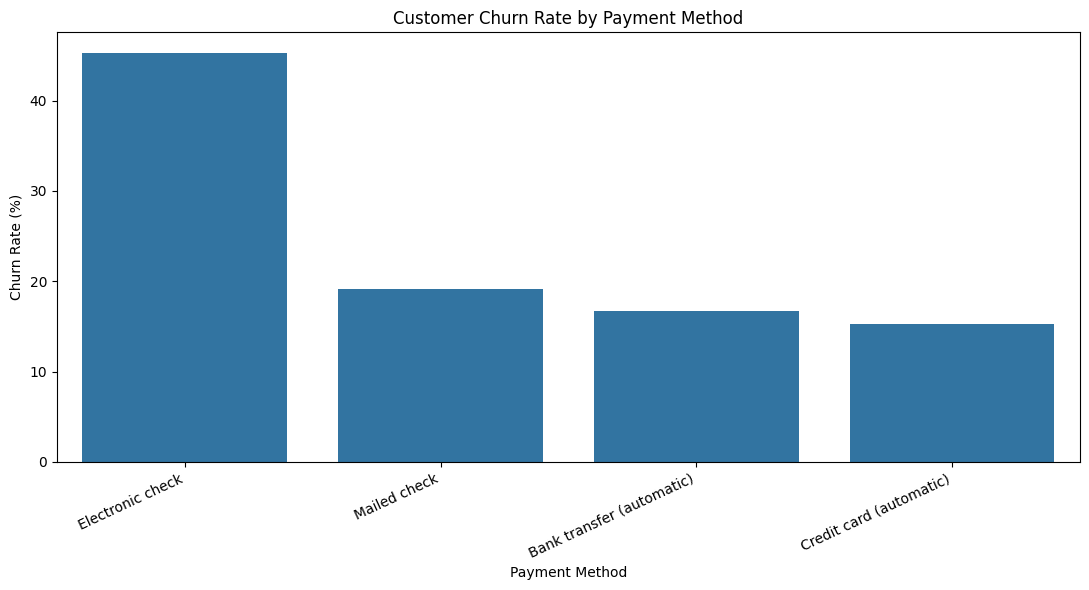

In [20]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=payment_analysis.reset_index(),
    x="PaymentMethod",
    y="churn_rate",
    errorbar=None
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [19]:
payment_analysis = df.groupby("PaymentMethod").agg(
    total_customers=("customerID", "count"),
    churned_customers=(
        "Churn",
        lambda x: (x == "Yes").sum()
    )
)

payment_analysis["churn_rate"] = (
    payment_analysis["churned_customers"]
    / payment_analysis["total_customers"]
) * 100

payment_analysis = payment_analysis.sort_values(
    by="churn_rate",
    ascending=False
)

print(payment_analysis.round(2))

                           total_customers  churned_customers  churn_rate
PaymentMethod                                                            
Electronic check                      2365               1071       45.29
Mailed check                          1612                308       19.11
Bank transfer (automatic)             1544                258       16.71
Credit card (automatic)               1522                232       15.24


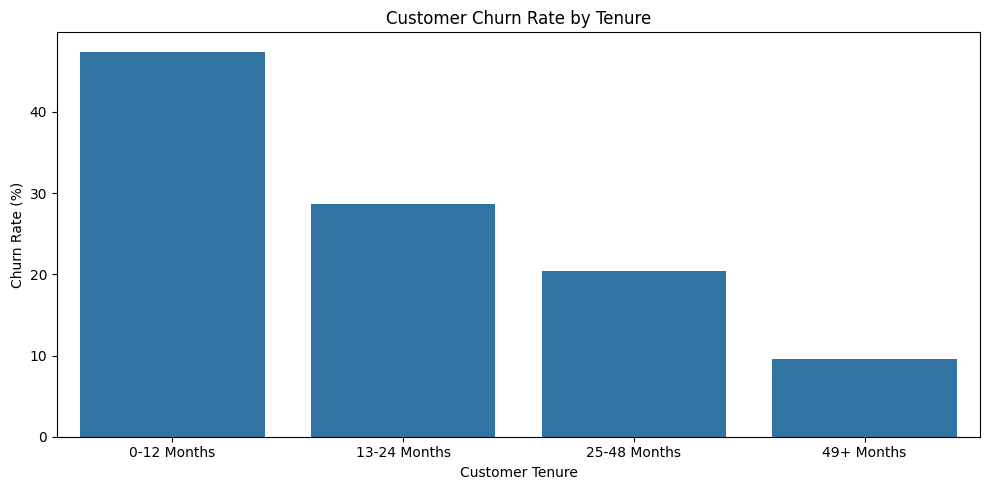

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tenure_analysis.reset_index(),
    x="tenure_group",
    y="churn_rate",
    errorbar=None
)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

In [17]:
tenure_analysis = df.groupby(
    "tenure_group",
    observed=True
).agg(
    total_customers=("customerID", "count"),
    churned_customers=(
        "Churn",
        lambda x: (x == "Yes").sum()
    )
)

tenure_analysis["churn_rate"] = (
    tenure_analysis["churned_customers"]
    / tenure_analysis["total_customers"]
) * 100

print(tenure_analysis.round(2))

              total_customers  churned_customers  churn_rate
tenure_group                                                
0-12 Months              2186               1037       47.44
13-24 Months             1024                294       28.71
25-48 Months             1594                325       20.39
49+ Months               2239                213        9.51


In [16]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, float("inf")],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49+ Months"
    ]
)

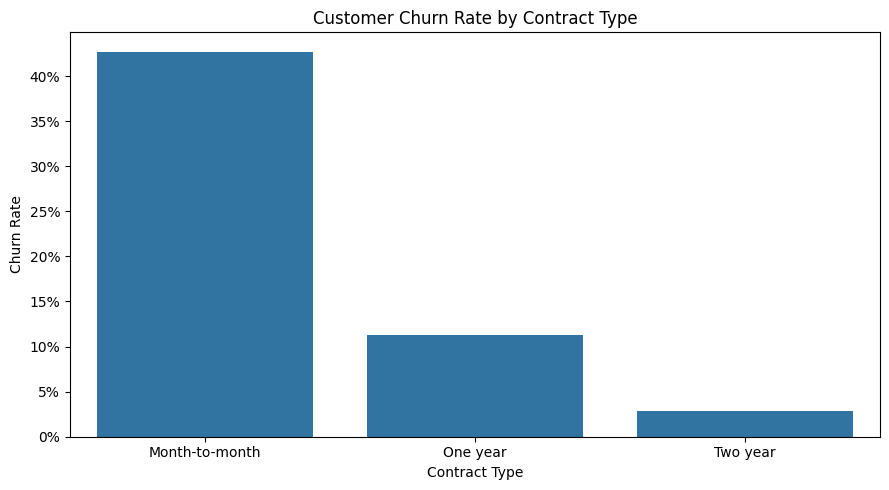

In [15]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Contract",
    y=df["Churn"].eq("Yes").astype(int),
    errorbar=None
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.tight_layout()
plt.show()

In [14]:
contract_analysis = df.groupby("Contract").agg(
    total_customers=("customerID", "count"),
    churned_customers=("Churn", lambda x: (x == "Yes").sum())
)

contract_analysis["churn_rate"] = (
    contract_analysis["churned_customers"]
    / contract_analysis["total_customers"]
) * 100

contract_analysis = contract_analysis.sort_values(
    by="churn_rate",
    ascending=False
)

print(contract_analysis.round(2))

                total_customers  churned_customers  churn_rate
Contract                                                      
Month-to-month             3875               1655       42.71
One year                   1473                166       11.27
Two year                   1695                 48        2.83


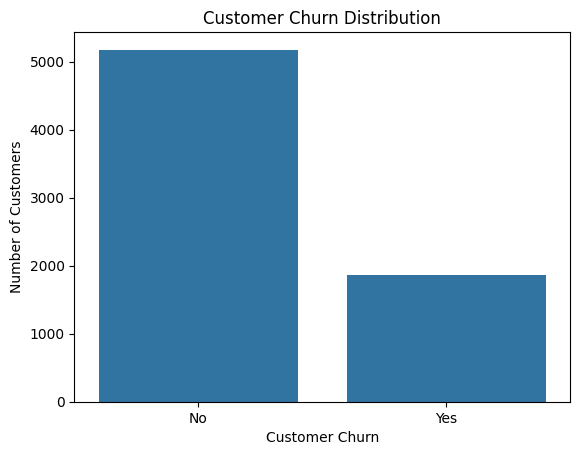

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

In [12]:
total_customers = len(df)

churned_customers = (df["Churn"] == "Yes").sum()

retained_customers = (df["Churn"] == "No").sum()

churn_rate = (
    churned_customers / total_customers
) * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print("Retained customers:", retained_customers)
print(f"Churn rate: {churn_rate:.2f}%")

Total customers: 7043
Churned customers: 1869
Retained customers: 5174
Churn rate: 26.54%


In [11]:
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

Dataset shape: (7043, 21)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  Paperl

In [10]:
df.loc[
    df["TotalCharges"].isnull(),
    ["customerID", "tenure", "TotalCharges", "Churn"]
]

,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,NaN,No
753,3115-CZMZD,0,NaN,No
936,5709-LVOEQ,0,NaN,No
1082,4367-NUYAO,0,NaN,No
1340,1371-DWPAZ,0,NaN,No
3331,7644-OMVMY,0,NaN,No
3826,3213-VVOLG,0,NaN,No
4380,2520-SGTTA,0,NaN,No
5218,2923-ARZLG,0,NaN,No
6670,4075-WKNIU,0,NaN,No


In [9]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Missing TotalCharges: 11


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7043
Number of columns: 21


In [2]:
df = pd.read_csv(
    "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!
